Laboratorio 7, Fisica Computacional

Juan Manuel Patiño

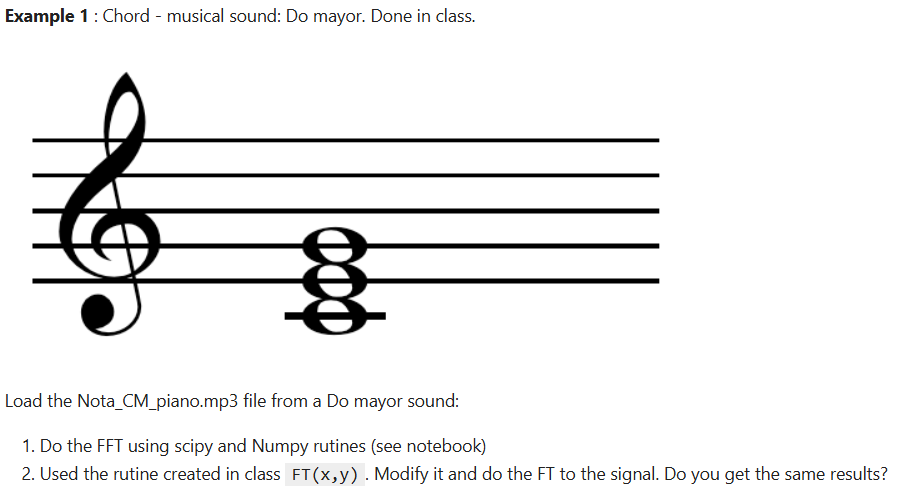

In [1]:
pip install playsound3

In [2]:
#librerias
from playsound3 import playsound
import librosa
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
import scipy.integrate as integrate
import pandas as pd
import math
from numba import njit
import cv2

Sample Rate: 44100
Signal Shape: (152064,)


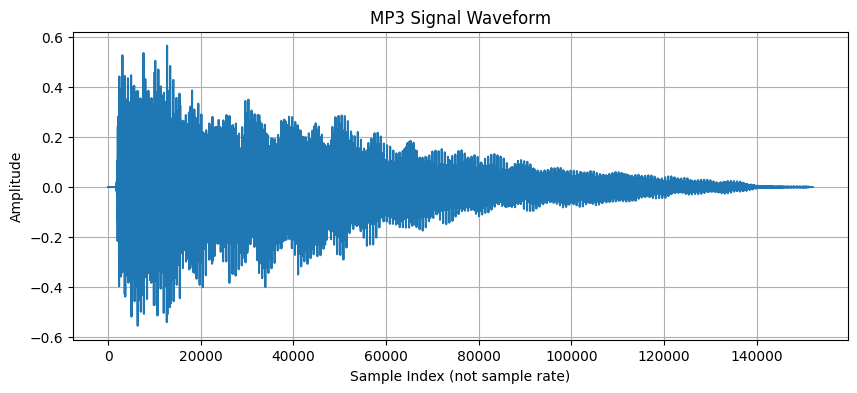

In [4]:
playsound('Nota_CM_piano.mp3')
signal, sr = librosa.load('Nota_CM_piano.mp3', sr=None)
print(f"Sample Rate: {sr}")
print(f"Signal Shape: {signal.shape}")
plt.figure(figsize=(10, 4))
plt.plot(signal)
plt.grid()
plt.title("MP3 Signal Waveform")
plt.xlabel("Sample Index (not sample rate)")
plt.ylabel("Amplitude")
plt.show()

In [5]:
y = signal
t = np.linspace(0, len(signal)/sr, len(signal))

def g(t,w):
    return 1./(2*np.pi)*np.exp(-1j*2*np.pi*w*t)

from scipy import interpolate

def FT(x,y):
    '''Integrate the Fourier Transform of f(t) at frequency w'''

    #Interpolate f(t) to integrate
    f_interp = interpolate.interp1d(x, y, kind='cubic', fill_value='extrapolate')
    ft = lambda t: f_interp(t)

    # range of t to integrate
    t = np.linspace(x.min(), x.max(), 400)

    # FRECUENCIES spectrum to looking for peaks
    w = np.linspace(100,1000,1000)

    df = []
    for i in range(len(w)):
        ARew = integrate.quad(lambda t: ft(t)*g(t,w[i]).real, t.min(), t.max())[0]
        AImw = integrate.quad(lambda t: ft(t)*g(t,w[i]).imag, t.min(), t.max())[0]
        AMP = np.sqrt(ARew**2 + AImw**2)
        ANG = np.arctan2(AImw, ARew)
        df.append([w[i], ARew, AImw, AMP, ANG])

    # DataFrame
    df = pd.DataFrame(df, columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])
    return df

/tmp/ipykernel_2344/4254894478.py:24: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  ARew = integrate.quad(lambda t: ft(t)*g(t,w[i]).real, t.min(), t.max())[0]
/tmp/ipykernel_2344/4254894478.py:25: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  AImw = integrate.quad(lambda t: ft(t)*g(t,w[i]).imag, t.min(), t.max())[0]
/tmp/ipykernel_2344/4254894478.py:25: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  AImw = integrate.quad(lambda t: ft(t)*g(t,w[i]).imag, t.min(), t.max())[0]
/tmp/ipykernel_2344/4254894478.py:24: Inte

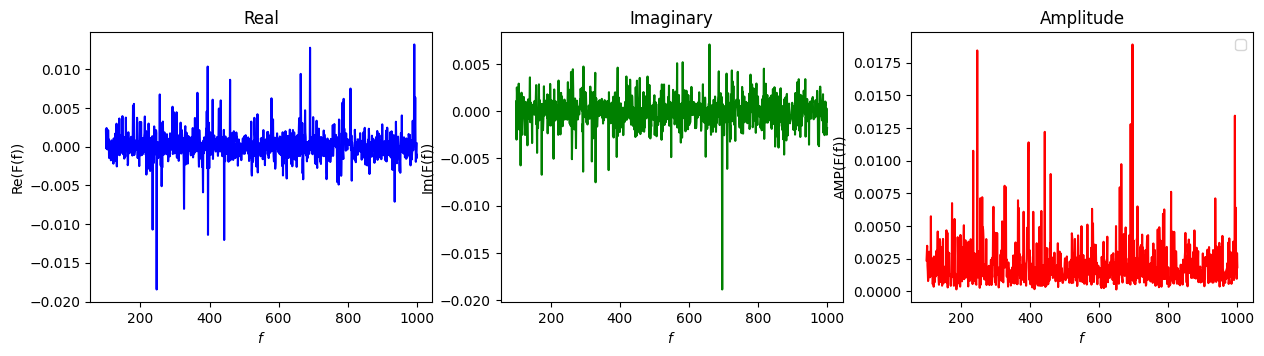

In [6]:
df = pd.DataFrame(FT(t, y), columns=['w', 'ReTw', 'ImTw', 'AMP', 'ANG'])

plt.figure(figsize=(15,3.5))
######## REAL ###########
plt.subplot(1,3,1)
plt.plot(df.w, df.ReTw,'b-')
plt.title('Real')
plt.xlabel('$f$')
plt.ylabel('Re(F(f))')
######### IMAG ##########
plt.subplot(1,3,2)
plt.plot(df.w, df.ImTw,'g-')
plt.title('Imaginary')
plt.xlabel('$f$')
plt.ylabel('Im(F(f))')
######### AMP ##########
plt.subplot(1,3,3)
plt.plot(df.w, df.AMP,'r-')
plt.title('Amplitude')
plt.xlabel('$f$')
plt.ylabel('AMP(F(f))')
plt.legend(loc='best')
plt.show()

### Trasformada Rapida de furier

La Transformada Discreta de Fourier (DFT) de una señal discreta $x_n$ de longitud $N$ se define formalmente como:

$$X_k = \sum_{n=0}^{N-1} x_n e^{-i \frac{2\pi}{N} k n} \quad \text{para } k = 0, 1, \dots, N-1$$

El algoritmo de Cooley-Tukey aprovecha una propiedad de simetría y periodicidad dividiendo el índice $n$ en muestras **pares** ($2m$) e **impares** ($2m+1$), asumiendo que $N$ es una potencia de 2:

$$X_k = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-i \frac{2\pi}{N} k (2m)} + \sum_{m=0}^{\frac{N}{2}-1} x_{2m+1} e^{-i \frac{2\pi}{N} k (2m+1)}$$

Factorizando los términos comunes y separando la parte impar, obtenemos dos DFTs más pequeñas de tamaño $\frac{N}{2}$:

$$X_k = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-i \frac{2\pi}{N/2} k m} + e^{-i \frac{2\pi}{N} k} \sum_{m=0}^{\frac{N}{2}-1} x_{2m+1} e^{-i \frac{2\pi}{N/2} k m}$$

Denominando a la transformada de los índices pares como $E_k$ y la de los impares como $O_k$, la ecuación se compacta de la siguiente manera:

$$X_k = E_k + W_N^k O_k$$

Donde $W_N^k = e^{-i \frac{2\pi}{N} k}$ se conoce como el **factor twiddle** (o factor de giro).

Gracias a la periodicidad de las exponenciales complejas, la segunda mitad del espectro ($k + \frac{N}{2}$) se calcula económicamente sin recalcular las sumas completas, utilizando la operación mariposa (*butterfly*):

$$X_{k + \frac{N}{2}} = E_k - W_N^k O_k$$




### Fundamento Matemático de la FFT (Cooley-Tukey) y Operación Mariposa

La Transformada Discreta de Fourier (DFT) de una señal discreta $x_n$ de longitud $N$ se define formalmente como:

$$X_k = \sum_{n=0}^{N-1} x_n e^{-i \frac{2\pi}{N} k n} \quad \text{para } k = 0, 1, \dots, N-1$$

El algoritmo de Cooley-Tukey divide el índice $n$ en muestras **pares** ($2m$) e **impares** ($2m+1$), asumiendo que $N$ es una potencia de 2:

$$X_k = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-j \frac{2\pi}{N} k (2m)} + \sum_{m=0}^{\frac{N}{2}-1} x_{2m+1} e^{-i \frac{2\pi}{N} k (2m+1)}$$

Factorizando los términos comunes y separando la parte impar, obtenemos dos DFTs más pequeñas de tamaño $\frac{N}{2}$ (denominadas $E_k$ para las pares y $O_k$ para las impares):

$$X_k = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-j \frac{2\pi}{N/2} k m} + e^{-j \frac{2\pi}{N} k} \sum_{m=0}^{\frac{N}{2}-1} x_{2m+1} e^{-i \frac{2\pi}{N/2} k m}$$

Que se expresa de forma compacta como:
$$X_k = E_k + W_N^k O_k$$

Donde $W_N^k = e^{-i \frac{2\pi}{N} k}$ es el **factor de giro**.





---

### Demostración 1: Periodicidad de la Sub-Transformada ($E_{k + \frac{N}{2}} = E_k$)

La sub-transformada par $E_k$ es una DFT de tamaño $\frac{N}{2}$ y está definida por:

$$E_k = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-i \frac{2\pi}{N/2} k m}$$

Si evaluamos esta expresión en la segunda mitad de las frecuencias, es decir, sustituyendo $k$ por $k + \frac{N}{2}$:

$$E_{k + \frac{N}{2}} = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-i \frac{2\pi}{N/2} \left(k + \frac{N}{2}\right) m}$$

Expandimos el argumento del exponente:

$$\frac{2\pi}{N/2} \left(k + \frac{N}{2}\right) m = \frac{4\pi}{N} k m + \frac{4\pi}{N} \left(\frac{N}{2}\right) m = \frac{2\pi}{N/2} k m + 2\pi m$$

Sustituyendo esto en la exponencial, podemos separar el producto:

$$e^{-j \left(\frac{2\pi}{N/2} k m + 2\pi m\right)} = e^{-j \frac{2\pi}{N/2} k m} \cdot e^{-j 2\pi m}$$

Dado que $m$ es un número entero, por la fórmula de Euler el término $e^{-j 2\pi m} = \cos(2\pi m) - j\sin(2\pi m) = 1$. Por lo tanto, nos queda:

$$E_{k + \frac{N}{2}} = \sum_{m=0}^{\frac{N}{2}-1} x_{2m} e^{-j \frac{2\pi}{N/2} k m} = E_k$$

---

### Demostración 2: Signo del Factor de Giro ($W_N^{k + \frac{N}{2}} = -W_N^k$)

El factor de giro se define como:

$$W_N^k = e^{-i \frac{2\pi}{N} k}$$

Evaluándolo para la frecuencia desplazada $k + \frac{N}{2}$:

$$W_N^{k + \frac{N}{2}} = e^{-i \frac{2\pi}{N} \left(k + \frac{N}{2}\right)}$$

Aplicando las propiedades de los exponentes, separamos la suma:

$$W_N^{k + \frac{N}{2}} = e^{-j \frac{2\pi}{N} k} \cdot e^{-i \frac{2\pi}{N} \frac{N}{2}}$$

Simplificando el segundo factor de la derecha ($\frac{2\pi}{N} \cdot \frac{N}{2} = \pi$):

$$W_N^{k + \frac{N}{2}} = W_N^k \cdot e^{-i \pi}$$

Aplicando la identidad de Euler ($e^{-j \pi} = \cos(\pi) - j\sin(\pi) = -1$):

$$W_N^{k + \frac{N}{2}} = W_N^k \cdot (-1) = -W_N^k$$

---

### Conclusión:

Combinando ambos resultados para calcular la segunda mitad del espectro ($X_{k + \frac{N}{2}}$):

$$X_{k + \frac{N}{2}} = E_{k + \frac{N}{2}} + W_N^{k + \frac{N}{2}} O_{k + \frac{N}{2}}$$

Sustituyendo $E_{k + \frac{N}{2}} = E_k$ y $W_N^{k + \frac{N}{2}} = -W_N^k$, obtenemos la ecuación final de la operación mariposa:

$$X_{k + \frac{N}{2}} = E_k - W_N^k O_k$$

In [7]:
@njit #este decorador es solamente para hacer mas rapida la unica parte del codigo que puede ser lenta
def W(k, N):

    angulo = -2.0 * math.pi * k / N
    return math.cos(angulo) + 1j * math.sin(angulo)

In [8]:
def TRDJ(x):
  N = len(x)

  if N<=1:
    return x

  A = x[::2]   # Elementos en posiciones pares
  B = x[1::2]  # Elementos en posiciones impares

  TA = TRDJ(A)
  TB = TRDJ(B)

  E = np.zeros(N//2, dtype=complex)
  O = np.zeros(N//2, dtype=complex)
  T = np.zeros(N, dtype=complex)

  for i in range(N//2):
    E[i] = TA[i]
    O[i] = TB[i]
    w = W(i,N)

    T[i] = E[i] + W(i, N) * O[i]
    T[i + N//2] = E[i] - W(i, N) * O[i]

  return T

In [9]:
%timeit TRDJ(y) #calculo del tiempo de ejecucion de la trasformada

'''
en el momento de hacer este codigo se demoro 3.63s en trasformar la nota do
'''

3.63 s ± 621 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


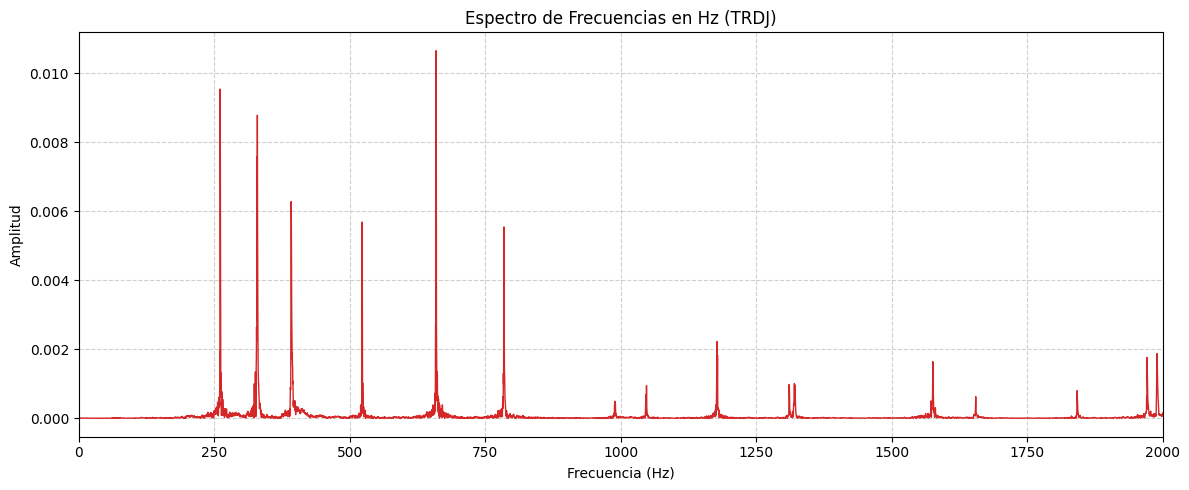

In [10]:
sample_rate = 44100
N = len(y)

# Como el audio no es potencia de 2, buscamos la siguiente potencia de 2 para la trasformada
N_fft = 2**int(np.ceil(np.log2(N)))

# Rellenamos con ceros si hace falta
y_padded = np.zeros(N_fft)
y_padded[:N] = y

# 3.
tRF = TRDJ(y_padded)/len(y_padded) #normalizamos
magnitudes = np.abs(tRF)

# 4. Crear el eje X en Hertz (solo la mitad positiva del espectro), recordemos que eso retorna una funcion par
frecuencias = np.fft.fftfreq(N_fft, d=1/sample_rate)

# Nos quedamos solo con la primera mitad, la otra mitad es la parte negativa que es exactamente igual
mitad = N_fft // 2
freqs_positivas = frecuencias[:mitad]
magnitudes_positivas = magnitudes[:mitad]

# 5. Graficar en Hz
plt.figure(figsize=(12, 5))
plt.plot(freqs_positivas, magnitudes_positivas, color='tab:red', linewidth=1)
plt.title("Espectro de Frecuencias en Hz (TRDJ)") #trasformada rapida de juan
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0, 2000)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

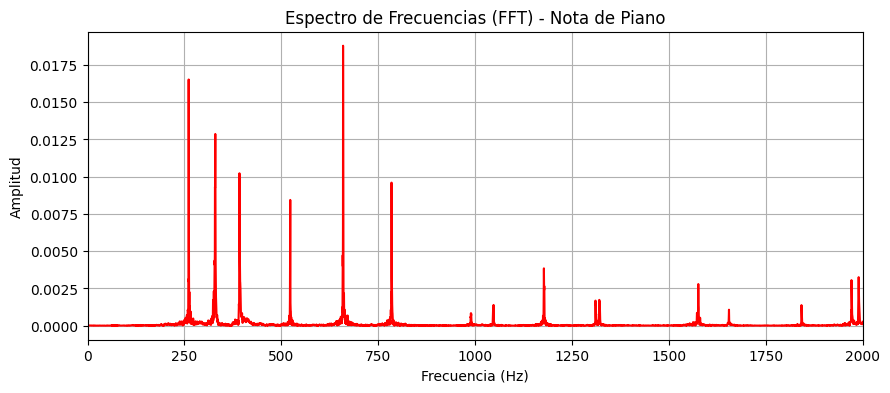

Frecuencia dominante detectada: 659.48 Hz


In [11]:
#codigo sacado del notebook del curso
import librosa
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

# 1. Cargar el archivo de audio
filename = 'Nota_CM_piano.mp3'
signal, sr = librosa.load(filename, sr=None)

# Para reproducir en Colab:
display(Audio(filename))

# 2. Calcular la Transformada Rápida de Fourier (FFT) para señales reales
N = len(signal)
fft_spectrum = np.fft.rfft(signal)
frequencies = np.fft.rfftfreq(N, d=1/sr) # Vector de frecuencias en Hz
amplitude = np.abs(fft_spectrum) / N      # Magnitud normalizada

# 3. Graficar el espectro en el rango de frecuencias audibles (0 a 2000 Hz)
plt.figure(figsize=(10, 4))
plt.plot(frequencies, amplitude, color='r')
plt.xlim(0, 2000) # Rango Relevante para notas de piano
plt.title("Espectro de Frecuencias (FFT) - Nota de Piano")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.grid(True)
plt.show()

# 4. Encontrar la frecuencia dominante (pico principal)
freq_dom = frequencies[np.argmax(amplitude)]
print(f"Frecuencia dominante detectada: {freq_dom:.2f} Hz")

###conlusiones del ejemplo 1:
* la trasformada formal y teorica es muy ineficiente por hacer uso de integrales y interpolacion haciendo que no podamos usar muchos puntos, esto causa que perdamos mucha informacion
* la trasformada rapida de furier que usamos solo hace uso de la simetrias de seno y coseno usandolas de forma recursiva, vemos que solo tenemos problemas en la normalizacion, esta solo dura unos 3s en ejecutarse y usa todos los puntos del ajuste, da un resultado similar a la trasformada de la libreria pero aun le quedan detalles
* la trasformada de la numpy es muy rapida facil de usar y va a ser el punto de referencia


----
* vamos a hacer uso de la trasformada rapida para resolver el ejercicio

### ejercicio 2
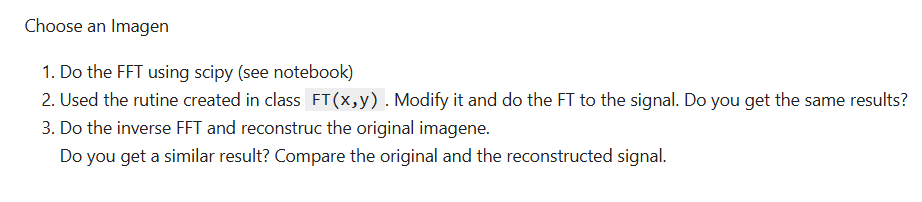

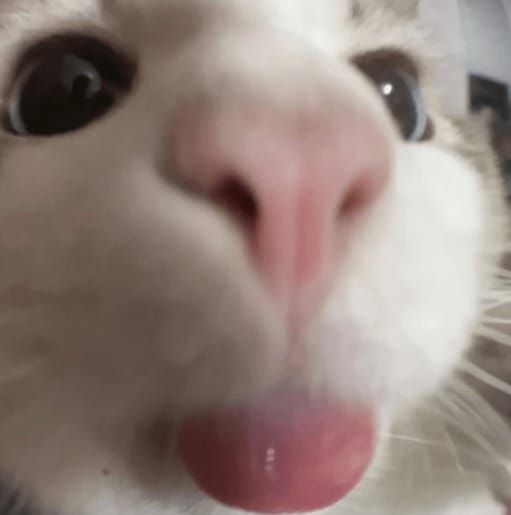

La ecuación de la Transformada Discreta de Fourier 2D para una matriz $f(x,y)$ de tamaño $M \times N$ es:

$$X(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$

$$X(u, v) = \sum_{x=0}^{M-1} e^{-j 2\pi \frac{ux}{M}} \left[ \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \frac{vy}{N}} \right]$$




In [13]:
#aplicamos la trasformada ya realizada para 1D pero aplicandola 2 veces y asi obtenemos la trasformada 2d
def trdj2D(matriz):

    alto, ancho = matriz.shape
    matriz_filas = np.zeros((alto, ancho), dtype=complex)

    #Aplicar TRDJ a cada fila
    for i in range(alto):
        matriz_filas[i, :] = TRDJ(matriz[i, :])

    resultado_2d = np.zeros((alto, ancho), dtype=complex)

    # Aplicar TRDJ a cada columna del resultado anterior
    for j in range(ancho):
        resultado_2d[:, j] = TRDJ(matriz_filas[:, j])

    return resultado_2d

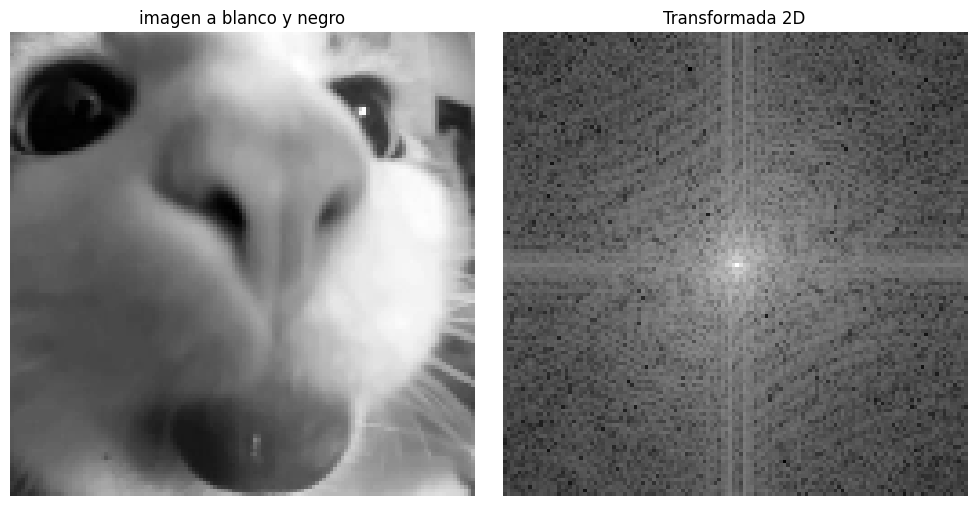

In [16]:
imagen_bgr = cv2.imread('/content/gatico123.jpeg')
imagen_rgb = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2RGB)

# Redimensionar a una potencia de 2 para que corra rápido con la recursión
imagen_rgb = cv2.resize(imagen_rgb, (128, 128))
canal_unico = imagen_rgb[:, :, 1].astype(float) #nos quedamos solo con 1 tono

# Aplicar nuestra transformada 2D
fft_resultado = trdj2D(canal_unico)

espectro_centrado = np.fft.fftshift(np.abs(fft_resultado))
espectro_log = np.log(1 + espectro_centrado)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(canal_unico, cmap='gray')
plt.title("imagen a blanco y negro")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(espectro_log, cmap='gray')
plt.title("Transformada 2D")
plt.axis('off')

plt.tight_layout()
plt.show()


#reconstrucion de la imagen

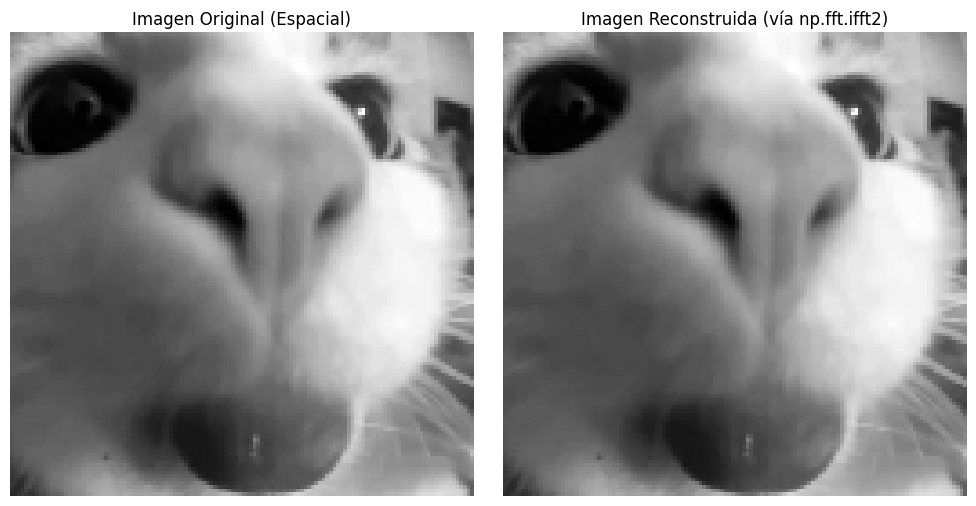

In [ ]:
imagen_reconstruida = np.fft.ifft2(fft_resultado)

# Como quedan residuos numéricos imaginarios muy pequeños por la precisión de punto flotante,
# nos quedamos únicamente con la parte real de la matriz.
imagen_original_recuperada = imagen_reconstruida.real
# 4. Visualizar resultados
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(canal_unico, cmap='gray')
plt.title("Imagen Original (Espacial)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_original_recuperada, cmap='gray')
plt.title("Imagen Reconstruida (vía np.fft.ifft2)")
plt.axis('off')

plt.tight_layout()
plt.show()

### conclusiones de el ejercicio 1
* se ve bastante bien luego de destrasformar
* una trasformada rapida artesanal puede competir con la de una libreria
* el costo computacional de la trasformada rapida es bastante bajo y su uso no solo esta limitado a cosas unidimensionales